In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
from sklearn.utils import resample
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import RobustScaler,StandardScaler # Corrected the spelling
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [3]:
!pip install statsmodels
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import Lasso
import statsmodels.api as sm

In [4]:
from sklearn.metrics import classification_report, r2_score,accuracy_score,recall_score,precision_score,f1_score,confusion_matrix,mean_absolute_error,mean_absolute_percentage_error

In [5]:
df=pd.read_csv('/content/mhealth_raw_data.csv')
df

,alx,aly,alz,glx,gly,glz,arx,ary,arz,grx,gry,grz,Activity,subject
0,2.1849,-9.6967,0.63077,0.103900,-0.84053,-0.68762,-8.6499,-4.5781,0.187760,-0.449020,-1.01030,0.034483,0.0,subject1
1,2.3876,-9.5080,0.68389,0.085343,-0.83865,-0.68369,-8.6275,-4.3198,0.023595,-0.449020,-1.01030,0.034483,0.0,subject1
2,2.4086,-9.5674,0.68113,0.085343,-0.83865,-0.68369,-8.5055,-4.2772,0.275720,-0.449020,-1.01030,0.034483,0.0,subject1
3,2.1814,-9.4301,0.55031,0.085343,-0.83865,-0.68369,-8.6279,-4.3163,0.367520,-0.456860,-1.00820,0.025862,0.0,subject1
4,2.4173,-9.3889,0.71098,0.085343,-0.83865,-0.68369,-8.7008,-4.1459,0.407290,-0.456860,-1.00820,0.025862,0.0,subject1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7854,2.5367,-9.3720,0.42135,-0.207790,-0.87430,-0.49902,-2.9275,-9.1337,1.626600,-0.068627,-0.95277,-0.349140,1.0,subject1
7855,2.4972,-9.6007,0.32619,-0.207790,-0.87430,-0.49902,-3.0006,-9.1559,1.406800,-0.058824,-0.92813,-0.357760,1.0,subject1
7856,2.2839,-9.5097,0.51610,-0.218920,-0.85553,-0.52063,-3.1036,-9.0320,1.798400,-0.058824,-0.92813,-0.357760,1.0,subject1
7857,2.4163,-9.6400,0.35466,-0.218920,-0.85553,-0.52063,-3.0904,-9.2324,1.757100,-0.058824,-0.92813,-0.357760,1.0,subject1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7859 entries, 0 to 7858
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   alx       7859 non-null   float64
 1   aly       7859 non-null   float64
 2   alz       7859 non-null   float64
 3   glx       7859 non-null   float64
 4   gly       7858 non-null   float64
 5   glz       7858 non-null   float64
 6   arx       7858 non-null   float64
 7   ary       7858 non-null   float64
 8   arz       7858 non-null   float64
 9   grx       7858 non-null   float64
 10  gry       7858 non-null   float64
 11  grz       7858 non-null   float64
 12  Activity  7858 non-null   float64
 13  subject   7858 non-null   object 
dtypes: float64(13), object(1)
memory usage: 859.7+ KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alx,7859.0,2.004327,1.544649,-20.95200,1.692950,2.101200,2.427000,19.944000
aly,7859.0,-9.544135,2.066327,-19.46800,-9.696850,-9.577000,-9.455250,7.062300
alz,7859.0,-0.051772,2.449761,-18.76100,0.013534,0.396250,0.588250,23.470000
glx,7859.0,-0.148363,0.153664,-0.64750,-0.224490,-0.200370,-0.009276,0.304270
gly,7858.0,-0.853513,0.105850,-1.05250,-0.898690,-0.872420,-0.842400,0.030019
glz,7858.0,-0.588162,0.134622,-1.09630,-0.683690,-0.540280,-0.504910,-0.058939
arx,7858.0,-3.780624,3.186295,-21.67300,-4.265850,-2.999950,-2.500250,7.875800
ary,7858.0,-5.777340,5.191991,-18.77900,-9.194500,-8.934400,-1.727875,11.320000
arz,7858.0,2.601412,3.284004,-9.75920,1.175425,1.661900,3.257125,18.754000
grx,7858.0,-0.216591,0.373493,-1.08430,-0.509800,-0.068627,0.098039,0.613730


In [8]:
df.isnull().sum()

,0
alx,0
aly,0
alz,0
glx,0
gly,1
glz,1
arx,1
ary,1
arz,1
grx,1


In [9]:
df.duplicated().sum()

np.int64(0)

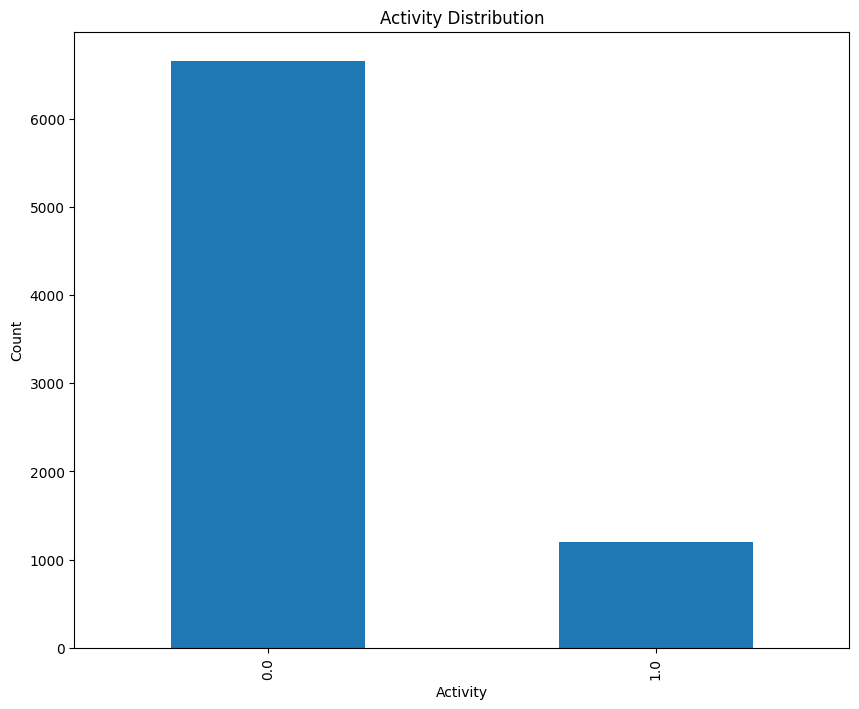

In [10]:
plt.figure(figsize=(10,8))
df['Activity'].value_counts().plot(kind='bar')
plt.xlabel('Activity')
plt.ylabel('Count')
plt.title('Activity Distribution')
plt.show()

In [11]:
data_activity_0=df[df['Activity']==0]
data_activity_else=df[df['Activity']!=0]

In [12]:
data_activity_0 = data_activity_0.sample(n=40000, replace=True) # Sample with replacement
df=pd.concat([data_activity_0,data_activity_else])

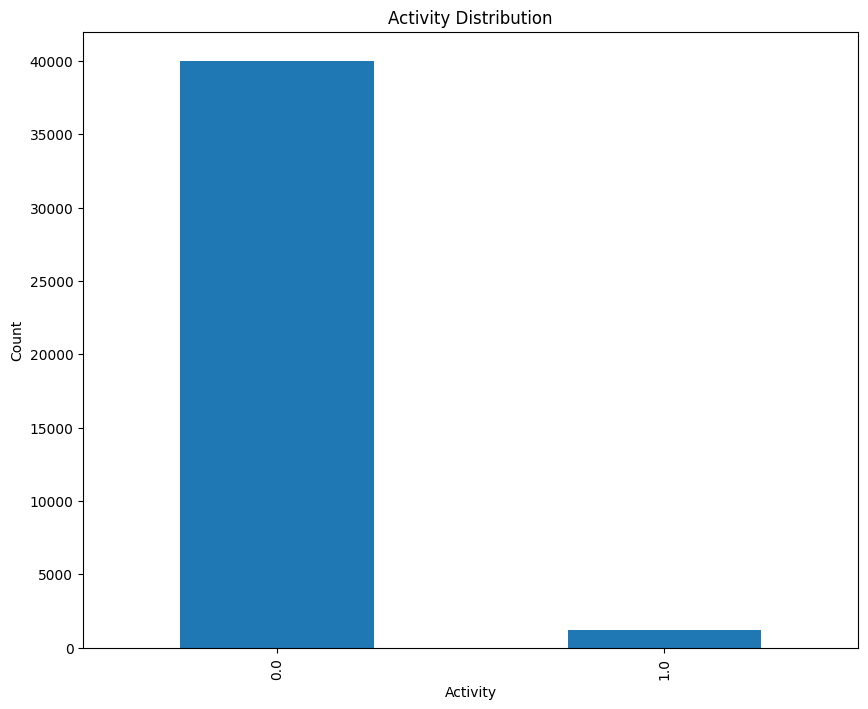

In [13]:
plt.figure(figsize=(10,8))
df['Activity'].value_counts().plot(kind='bar')
plt.xlabel('Activity')
plt.ylabel('Count')
plt.title('Activity Distribution')
plt.show()

In [14]:
len(df)

41203

In [15]:
activity_label={
    0:'Walking',
    1:'Walking upstairs',
    2:'Walking downstairs',
    3:'Sitting',
    4:'Standing',
    5:'Laying',
    6:'Jump'
}

======================Walking upstairs - a======================


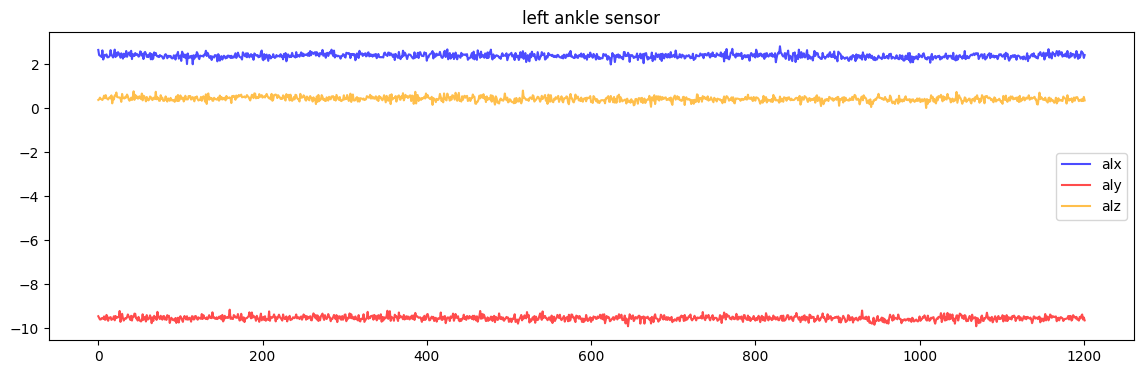

======================Walking upstairs - g======================


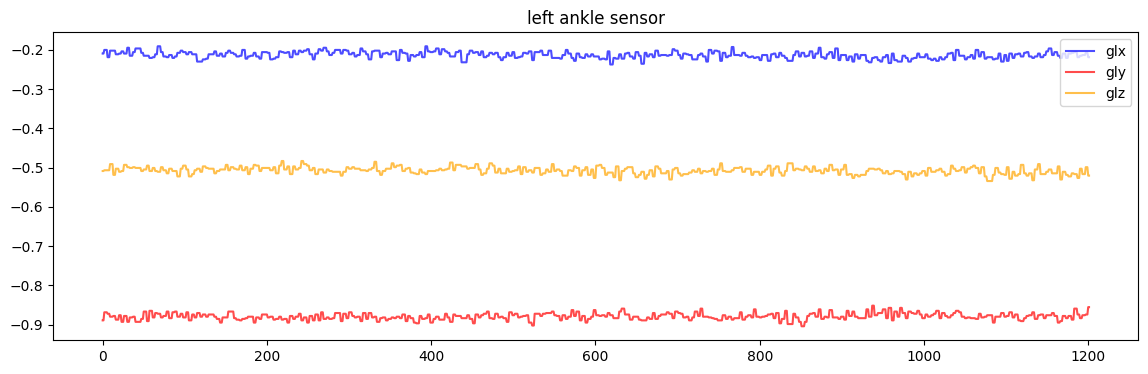

======================Walking downstairs - a======================


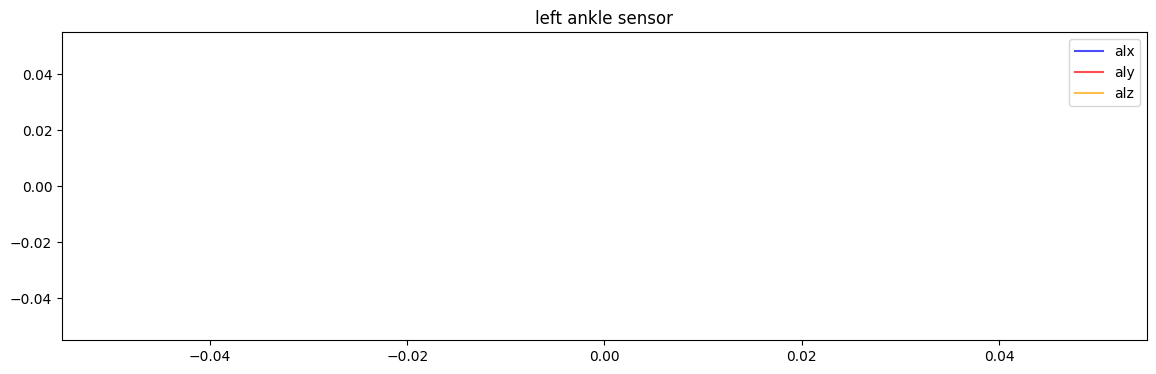

======================Walking downstairs - g======================


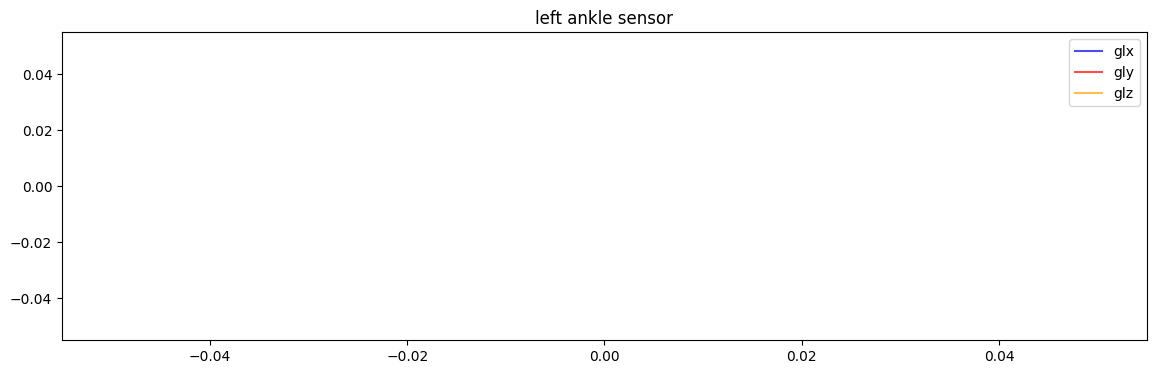

======================Sitting - a======================


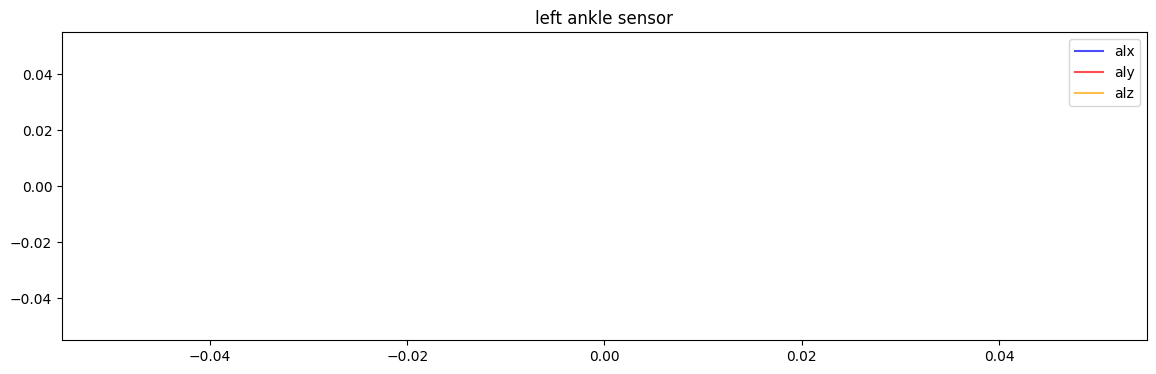

======================Sitting - g======================


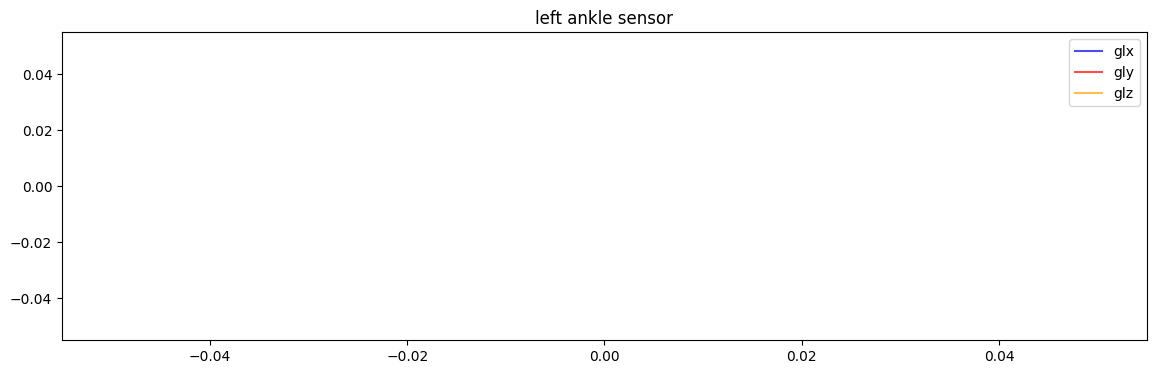

======================Standing - a======================


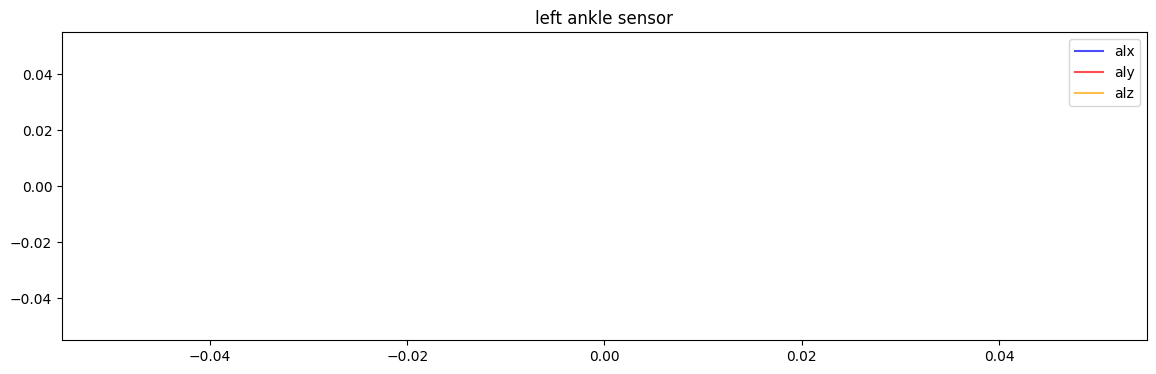

======================Standing - g======================


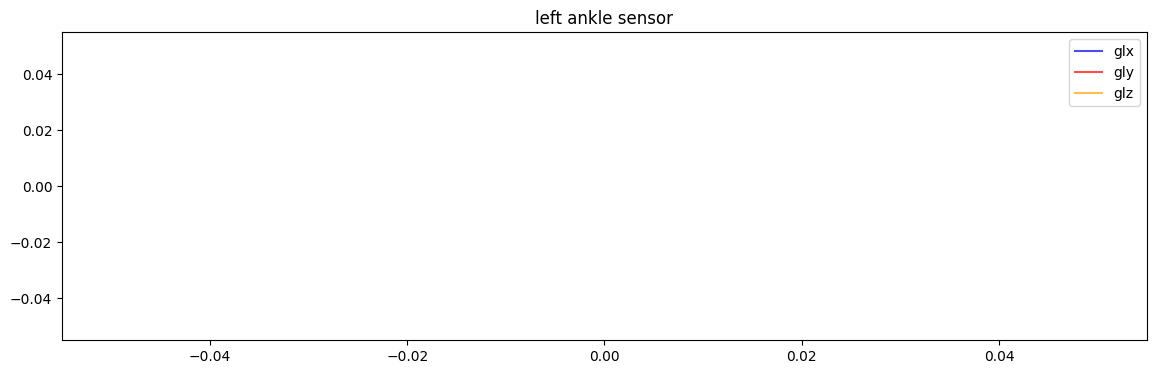

======================Laying - a======================


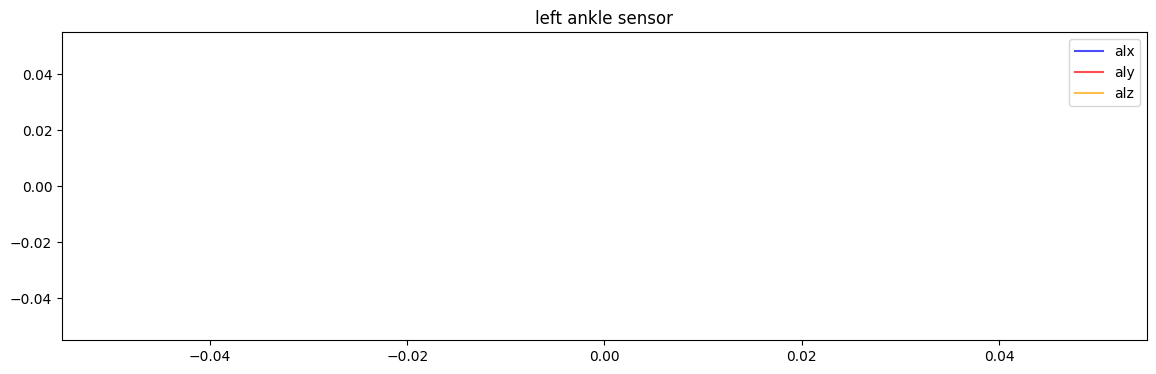

======================Laying - g======================


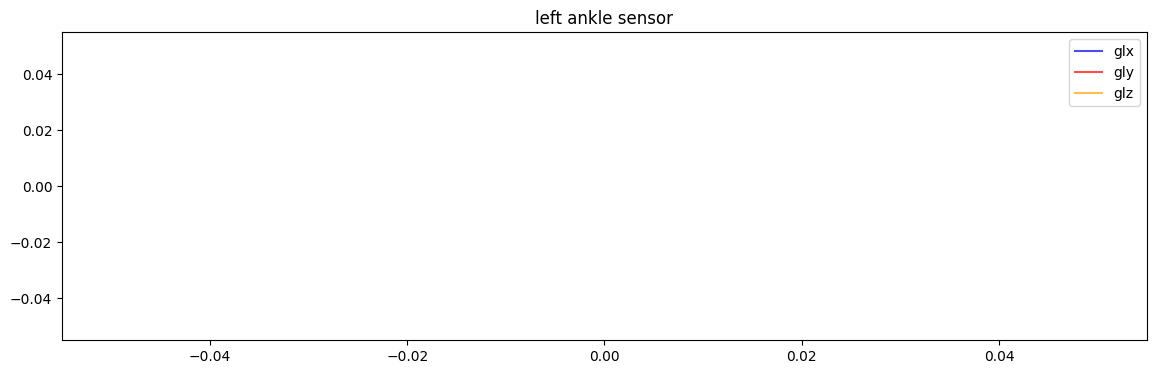

======================Jump - a======================


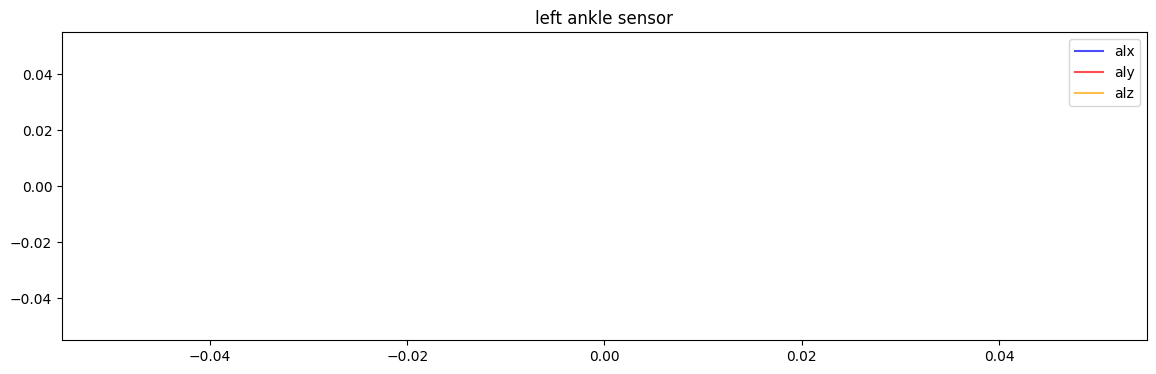

======================Jump - g======================


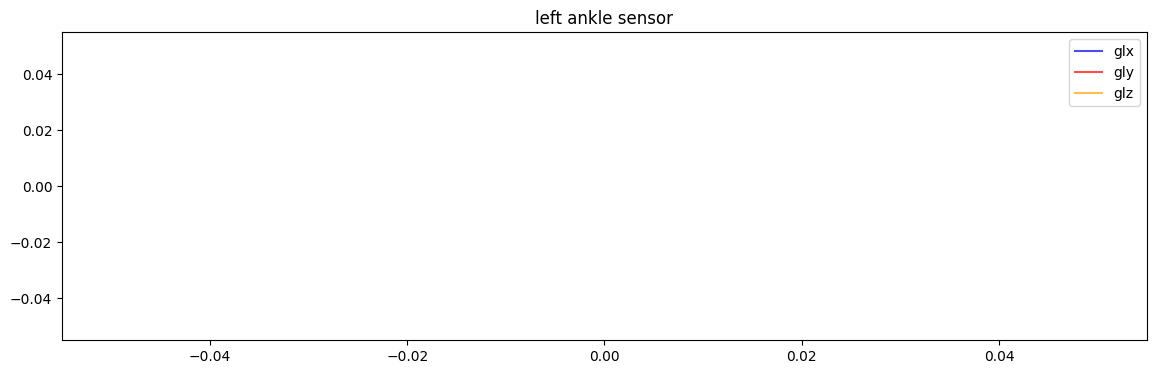

In [16]:
subject1=df[df['subject']=='subject1']
readings=['a','g']

# Iterate through the keys of the activity_label dictionary
for i in activity_label.keys():
    # Skip activity 0 if you don't want to plot it, based on the original range start of 1.
    # If you want to include activity 0, remove this if condition.
    if i == 0:
        continue

    for r in readings:
      print(f"======================{activity_label[i]} - {r}======================")
      plt.figure(figsize=(14,4))
      # Removed the incorrect subplot plotting command
      plt.plot(subject1[subject1['Activity']==i].reset_index(drop=True)[r + "lx"],color = "blue",alpha=0.7,label= r +"lx")
      plt.plot(subject1[subject1['Activity']==i].reset_index(drop=True)[r + "ly"],color = "red",alpha=0.7,label= r +"ly")
      plt.plot(subject1[subject1['Activity']==i].reset_index(drop=True)[r + "lz"],color = "orange",alpha=0.7,label= r +"lz")
      plt.title("left ankle sensor")
      plt.legend()
      plt.show()

======================Walking upstairs - a======================


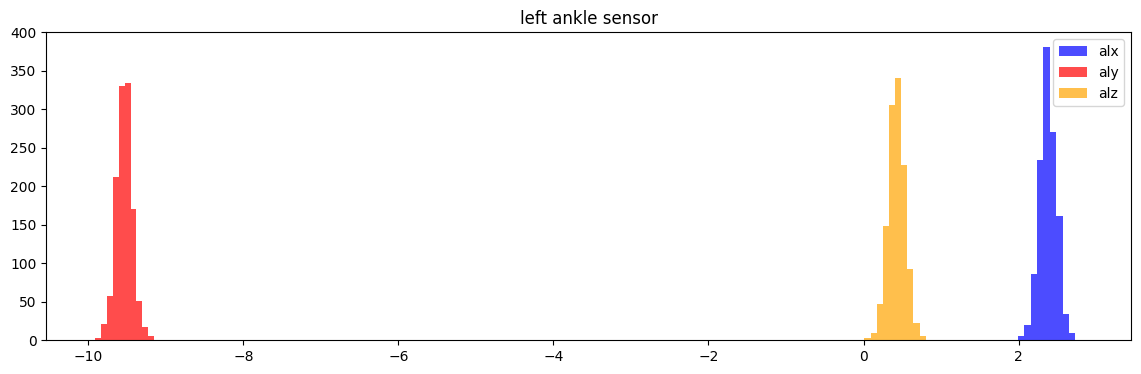

======================Walking upstairs - g======================


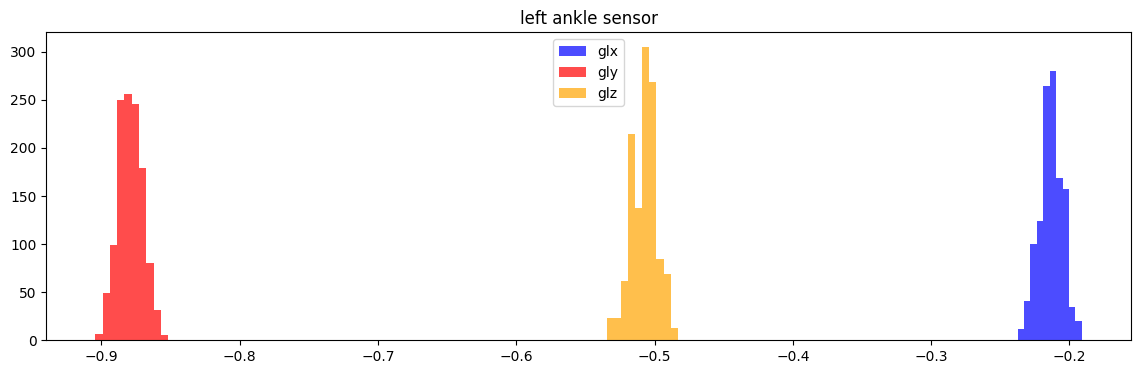

======================Walking downstairs - a======================


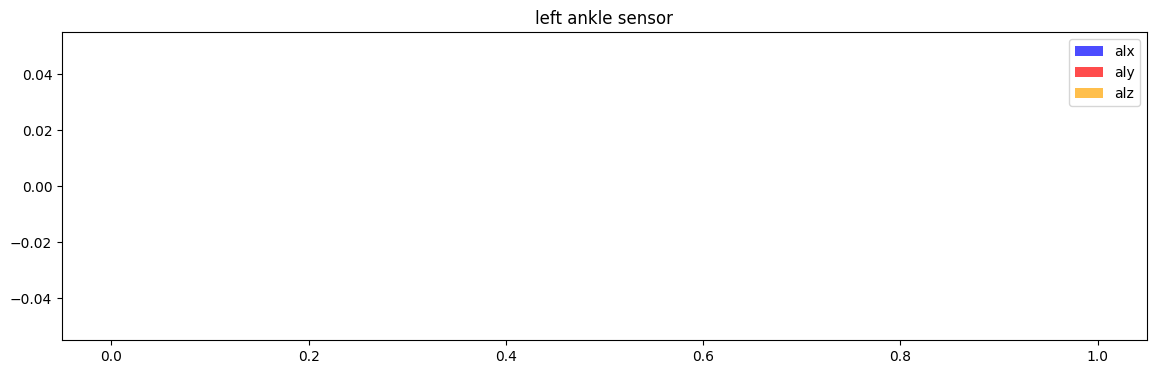

======================Walking downstairs - g======================


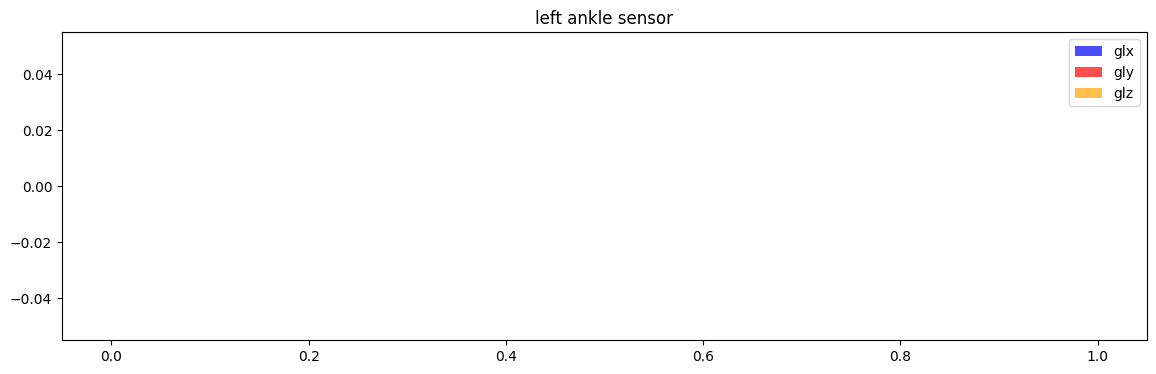

======================Sitting - a======================


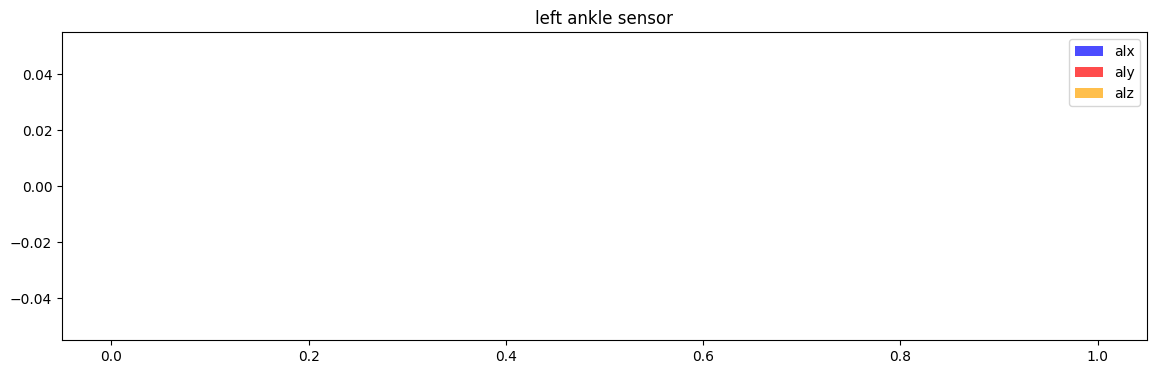

======================Sitting - g======================


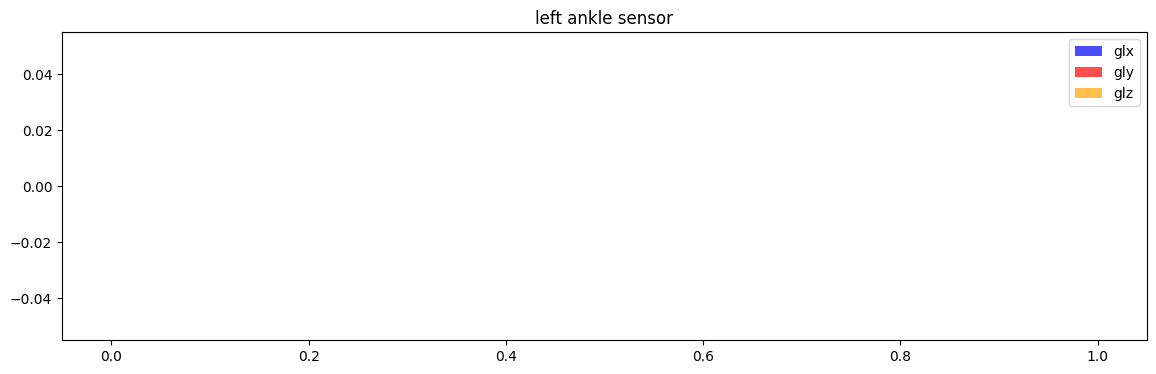

======================Standing - a======================


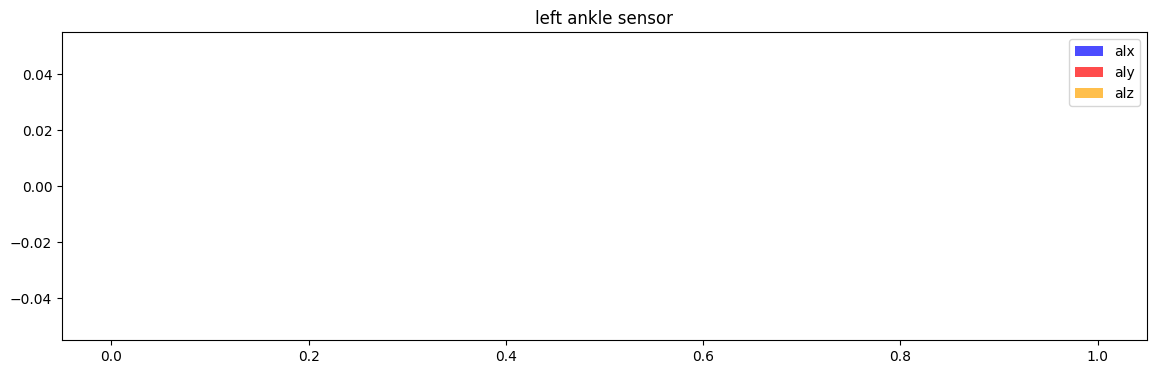

======================Standing - g======================


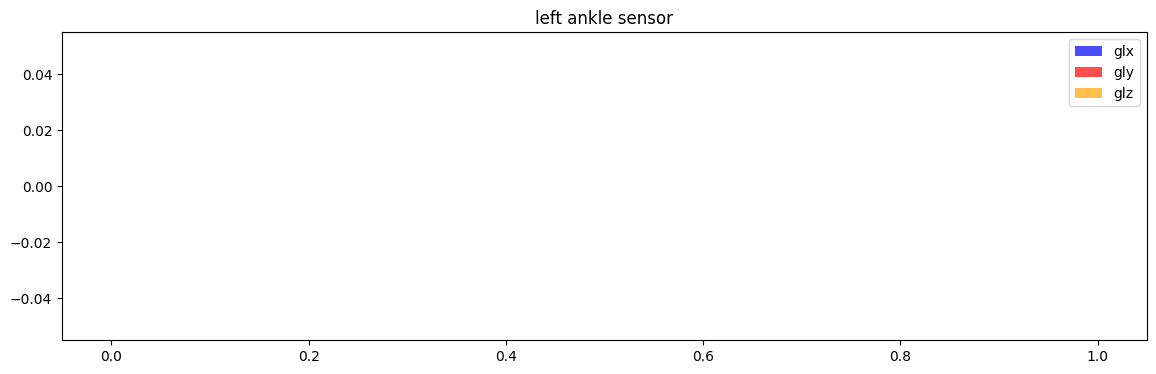

======================Laying - a======================


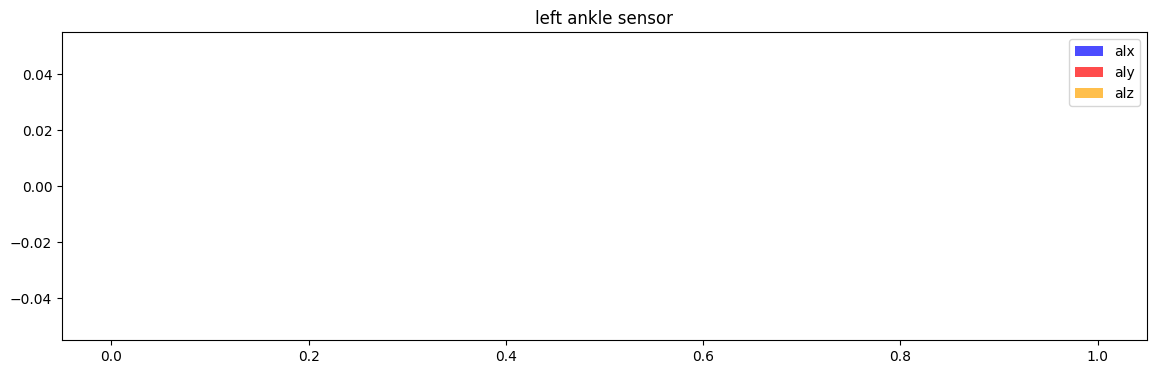

======================Laying - g======================


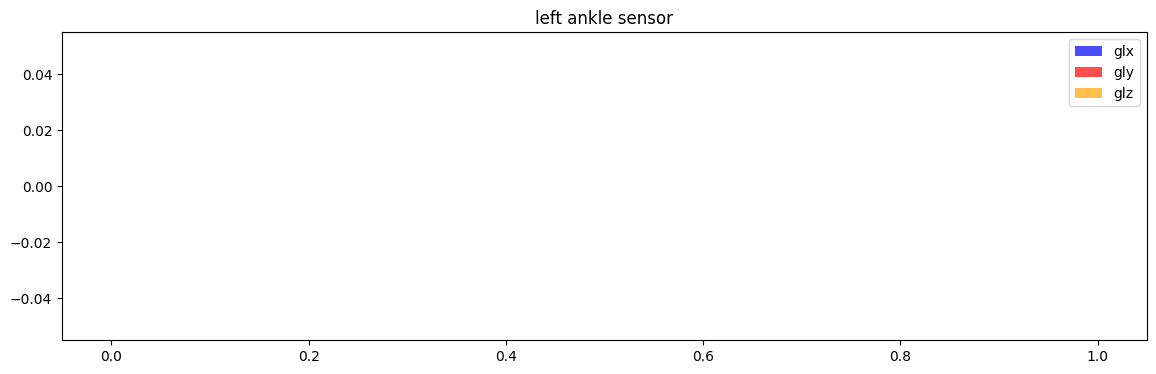

======================Jump - a======================


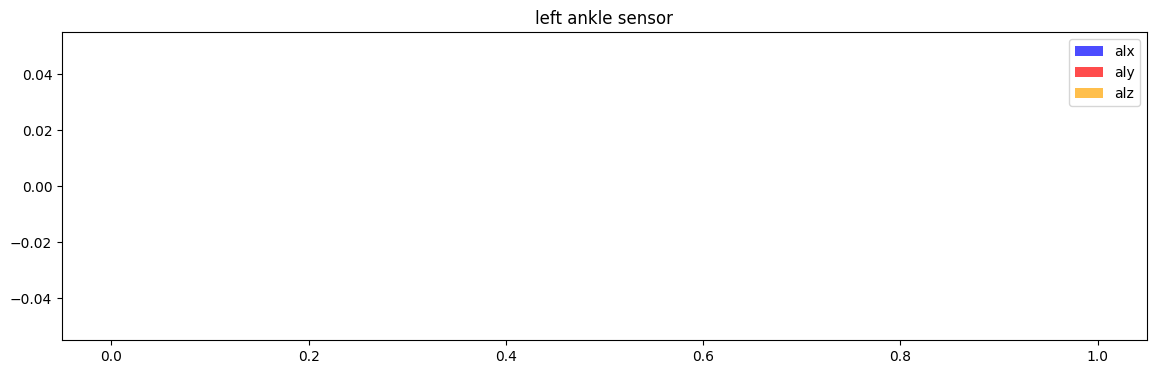

======================Jump - g======================


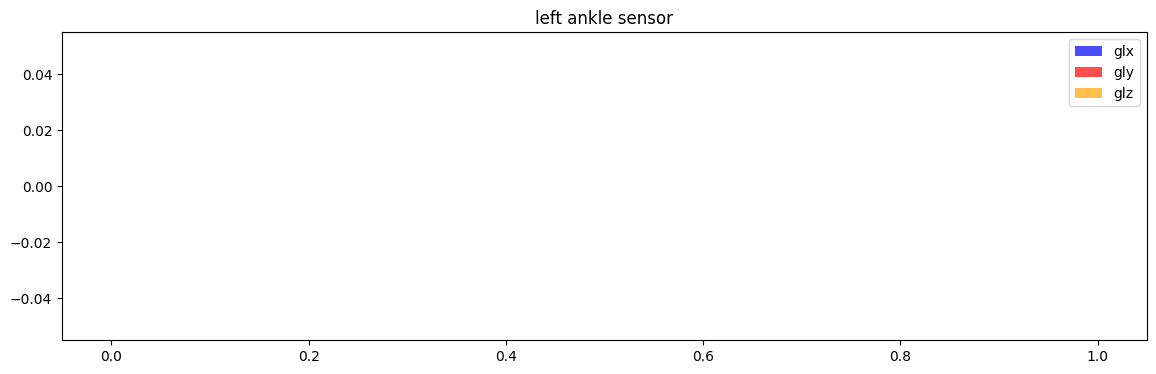

In [17]:
subject1=df[df['subject']=='subject1']
readings=['a','g']

# Iterate through the keys of the activity_label dictionary
for i in activity_label.keys():
    # Skip activity 0 if you don't want to plot it, based on the original range start of 1.
    # If you want to include activity 0, remove this if condition.
    if i == 0:
        continue

    for r in readings:
      print(f"======================{activity_label[i]} - {r}======================")
      plt.figure(figsize=(14,4))
      # Removed the incorrect subplot plotting command
      plt.hist(subject1[subject1['Activity']==i].reset_index(drop=True)[r + "lx"],color = "blue",alpha=0.7,label= r +"lx")
      plt.hist(subject1[subject1['Activity']==i].reset_index(drop=True)[r + "ly"],color = "red",alpha=0.7,label= r +"ly")
      plt.hist(subject1[subject1['Activity']==i].reset_index(drop=True)[r + "lz"],color = "orange",alpha=0.7,label= r +"lz")
      plt.title("left ankle sensor")
      plt.legend()
      plt.show()

In [18]:
# Corrected the column name to 'Activity' and the assignment
df['Activity'] = df['Activity'].replace([0, 1, 2, 3, 4, 5, 6],
                                        ['Walking',
                                         'Walking upstairs',
                                         'Walking downstairs',
                                         'Sitting',
                                         'Standing',
                                         'Laying',
                                         'Jump'])

In [19]:
df["Activity"]

,Activity
5424,Walking
1921,Walking
1290,Walking
5411,Walking
2959,Walking
...,...
7854,Walking upstairs
7855,Walking upstairs
7856,Walking upstairs
7857,Walking upstairs


In [20]:
df.Activity.value_counts()

,count
Activity,
Walking,40000
Walking upstairs,1202


<Axes: ylabel='count'>

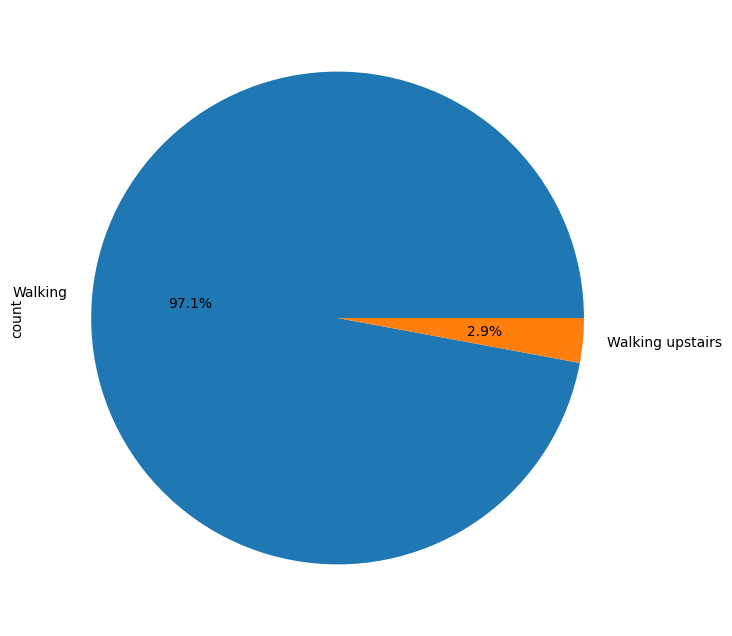

In [21]:
plt.figure(figsize=(12,8))
round(df["Activity"].value_counts()/df.shape[0]*100,2).plot.pie(autopct="%2.1f%%")


In [22]:
df1=df.copy()
for feature in df1.columns[:-2]:
  # Ensure the column is numeric before calculating quantiles
  # Coerce errors to NaN, and then drop rows with NaN in that column for both df and df1
  df[feature] = pd.to_numeric(df[feature], errors='coerce')
  df.dropna(subset=[feature], inplace=True)

  df1[feature] = pd.to_numeric(df1[feature], errors='coerce')
  df1.dropna(subset=[feature], inplace=True)

  # Properly indent the code belonging to the for loop
  lower_range = np.quantile(df[feature],0.01)
  upper_range = np.quantile(df[feature],0.99)
  print(feature,"range:",lower_range,'to',upper_range)

  df1=df1.drop(df1[(df1[feature ]> upper_range) | (df1[feature] < lower_range)].index,axis=0)
  print("shape",df1.shape)

alx range: -3.3482 to 7.7855
shape (40390, 14)
aly range: -19.155 to -0.05725423999995658
shape (39707, 14)
alz range: -12.431 to 3.9558
shape (39278, 14)
glx range: -0.51763 to 0.20594
shape (38484, 14)
gly range: -1.0038 to -0.41089880000000384
shape (38032, 14)
glz range: -1.0156610000000001 to -0.26326
shape (37759, 14)
arx range: -12.87 to 3.719480999999955
shape (37106, 14)
ary range: -18.605 to 7.6634
shape (36608, 14)
arz range: -4.2005 to 11.175999999999998
shape (36016, 14)
grx range: -1.0255 to 0.35098
shape (35378, 14)
gry range: -1.1704 to 1.0657
shape (34937, 14)
grz range: -0.63578 to 1.1099
shape (34262, 14)


In [23]:
df1

,alx,aly,alz,glx,gly,glz,arx,ary,arz,grx,gry,grz,Activity,subject
5424,1.7330,-9.4996,0.53193,-0.311690,-0.92871,-0.49509,-1.16750,-4.67190,8.8081,-0.621570,-0.85010,0.53879,Walking,subject1
1921,2.5598,-9.3094,0.74763,0.118740,-0.84240,-0.60904,-2.78070,-8.79380,1.6228,0.243140,-1.11290,-0.23060,Walking,subject1
5411,1.5497,-9.5193,0.54995,-0.287570,-0.93433,-0.47741,-0.92803,0.01928,2.9280,-0.703920,-0.59138,0.70474,Walking,subject1
2959,1.5619,-9.5972,0.67117,-0.217070,-0.85178,-0.54028,-2.66110,-9.35840,1.1571,0.247060,-1.06980,-0.27155,Walking,subject1
1032,2.9240,-9.3825,0.36220,-0.012987,-0.85741,-0.67583,-3.74240,-9.33140,1.8563,0.233330,-1.09650,-0.19397,Walking,subject1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7853,2.5874,-9.4324,0.32509,-0.207790,-0.87430,-0.49902,-3.05030,-9.10290,1.7115,-0.068627,-0.95277,-0.34914,Walking upstairs,subject1
7854,2.5367,-9.3720,0.42135,-0.207790,-0.87430,-0.49902,-2.92750,-9.13370,1.6266,-0.068627,-0.95277,-0.34914,Walking upstairs,subject1
7855,2.4972,-9.6007,0.32619,-0.207790,-0.87430,-0.49902,-3.00060,-9.15590,1.4068,-0.058824,-0.92813,-0.35776,Walking upstairs,subject1
7856,2.2839,-9.5097,0.51610,-0.218920,-0.85553,-0.52063,-3.10360,-9.03200,1.7984,-0.058824,-0.92813,-0.35776,Walking upstairs,subject1


In [24]:
le=LabelEncoder()
df1['subject']=le.fit_transform(df1['subject'])

In [25]:
# Corrected the column name to 'Activity' and the assignment
df['Activity'] = df['Activity'].replace([0, 1, 2, 3, 4, 5, 6],
                                        ['Walking',
                                         'Walking upstairs',
                                         'Walking downstairs',
                                         'Sitting',
                                         'Standing',
                                         'Laying',
                                         'Jump'])

# Check the unique values and their types in the 'Activity' column
print(df['Activity'].unique())
print(df['Activity'].apply(type).unique())

# If the unique types still include float or other non-string types,
# investigate why the replacement didn't cover all cases.
# One possible reason is the presence of NaN values or other unexpected data.
# You can handle potential NaN values by filling them before encoding,
# although the error message specifically points to float and str.
# For example, to fill NaN with a placeholder string:
# df['Activity'] = df['Activity'].fillna('Unknown').astype(str)

# Ensure the 'Activity' column is of string type before encoding
df['Activity'] = df['Activity'].astype(str)

le=LabelEncoder()
# Apply LabelEncoder to the 'Activity' column
df['Activity']= le.fit_transform(df['Activity'])

['Walking' 'Walking upstairs']
[<class 'str'>]


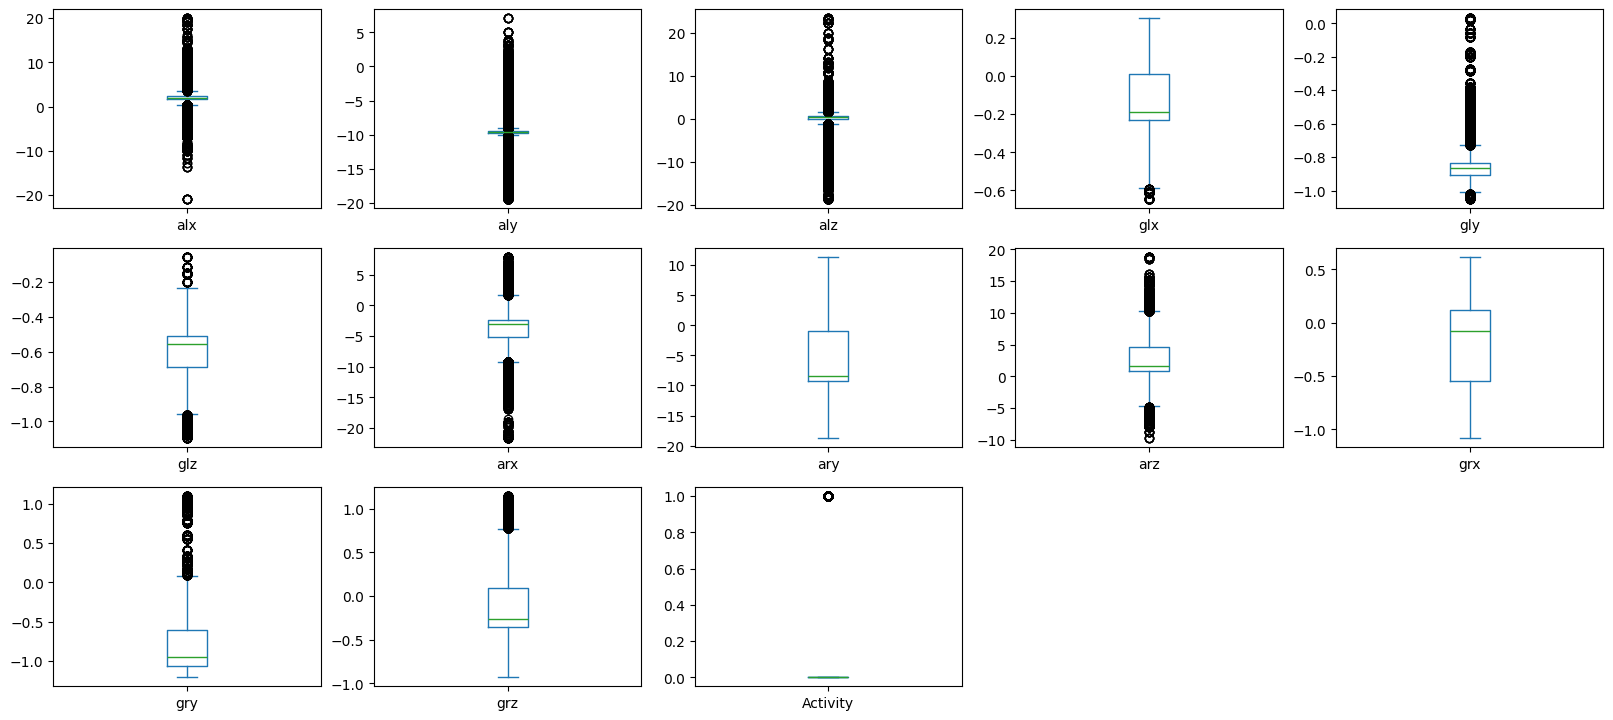

In [26]:
df.plot(kind='box',subplots=True,layout=(5,5),figsize=(20,15))
plt.show()

In [27]:
x= df.drop(["Activity","subject"],axis=1).values
y=df['Activity'].values

In [28]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25)

In [29]:
ro_scalar=RobustScaler()
# Fit the scaler on the training data and transform it
x_train_scaled=ro_scalar.fit_transform(x_train)
# Transform the test data using the fitted scaler
x_test_scaled=ro_scalar.transform(x_test)

In [30]:
def resultsSummarizer(y_true,y_pred,cm_en = True):
  cm=confusion_matrix(y_true,y_pred)
  acc=accuracy_score(y_true,y_pred)
  prec=precision_score(y_true,y_pred,average='macro')
  rec=recall_score(y_true,y_pred,average='macro')
  f1=f1_score(y_true,y_pred,average='macro')

  ply.figure(figsize=(15,15))

  sns.heatmap(cm, annot=True,cmap="Blues",xticklabels=activity_label.values(),yticklabels=activity_label.values())
  plt.show()

  print(classification_report(y_true,y_pred))

  print(f'Accuracy Score:' +'{:.4%}'.format(acc))
  print(f'Precision Score:' +'{:.4%}'.format(prec))
  print(f'Recall Score:' +'{:.4%}'.format(rec))
  print(f'F1 Score:' +'{:.4%}'.format(f1))

In [31]:
# Before splitting the data, handle missing values.
# Drop rows with any NaN values in the DataFrame.
df.dropna(inplace=True)

# After dropping NaNs, re-define x and y
x = df.drop(["Activity", "subject"], axis=1).values
y = df['Activity'].values

# The rest of your code for splitting, scaling, and training remains the same
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=25)

ro_scalar = RobustScaler()
# Fit the scaler on the training data and transform it
x_train_scaled = ro_scalar.fit_transform(x_train)
# Transform the test data using the fitted scaler
x_test_scaled = ro_scalar.transform(x_test)

lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)


LogisticRegression()

In [32]:
lr.score(x_train,y_train)

0.2927605216504359

In [33]:
lr.score(x_test,y_test)

0.48

In [34]:
lr2=LogisticRegression()
lr2.fit(x_train_scaled,y_train)

LogisticRegression()

In [35]:
lr2.score(x_train_scaled,y_train)

0.9702018116909925

In [36]:
lr2.score(x_test_scaled,y_test)

0.96

In [37]:
y_pred=lr2.predict(x_test_scaled)

In [38]:
def resultsSummarizer(y_true,y_pred,cm_en = True):
  cm=confusion_matrix(y_true,y_pred)
  acc=accuracy_score(y_true,y_pred)
  prec=precision_score(y_true,y_pred,average='macro')
  rec=recall_score(y_true,y_pred,average='macro')
  f1=f1_score(y_true,y_pred,average='macro')

  # Corrected ply to plt
  plt.figure(figsize=(15,15))

  sns.heatmap(cm, annot=True,cmap="Blues",xticklabels=activity_label.values(),yticklabels=activity_label.values())
  plt.show()

  print(classification_report(y_true,y_pred))

  print(f'Accuracy Score:' +'{:.4%}'.format(acc))
  print(f'Precision Score:' +'{:.4%}'.format(prec))
  print(f'Recall Score:' +'{:.4%}'.format(rec))
  print(f'F1 Score:' +'{:.4%}'.format(f1))